# V100 LTB 정책 적용월 백테스트: 12개월 → 60개월

기존 24→60 운영 Notebook과 분리된 개발 실험입니다. 개발 DB의 정책 적용월을 기준으로 예측하며, 개발 스냅샷에 저장된 수요를 관측값으로 사용합니다. 실제 승인일이나 운영 환경 성능에 대한 검증은 아닙니다.

## 1. 평가 설계

2024년 1·2·3월을 각각 보류해 순서대로 평가합니다. 입력은 정책 적용월 직전 12개월이고, 예측 1개월 차는 적용월입니다. 학습에는 평가월 시작 전에 60개월 관측 기간이 끝나고 72개월 기록이 완전한 부품만 사용합니다. 비교 기준은 직전 12개월 월평균을 60개월 동안 유지하는 방식입니다.

운영 모델에서 입력 길이만 12개월로 맞췄습니다. K-Means K=3으로 월별 비중을 학습하고 Random Forest로 패턴을 배정합니다. 12개월 월평균×60에 부품별 총량 보정 계수를 적용합니다. 모델·군집 수·보정 강도는 평가 데이터로 선택하지 않습니다.

## 2. 읽기 전용으로 받은 개발 데이터

정책 이력과 수요 원천을 회사·법인·사이트·자재로 연결했습니다. 현재 개발 DB V100의 삭제되지 않은 수요를 월별 합계로 집계하되, 원천 행이 없는 달은 생성하지 않았습니다. 수량은 EA입니다. 출처 표식이 다른 원천 기록은 별도로 집계하며, 한 개의 역사적 운영 원천으로 간주하지 않습니다.

In [1]:
import hashlib
import json
import os
from datetime import date
from pathlib import Path

from IPython.display import Markdown, display
import numpy as np
import polars as pl

root = Path(os.environ.get("LTB_DEV12_ROOT", "/private/tmp/ltb_dev12_experiment_20261124"))
extract = root / "monthly_scope_V100_live_development.csv"
manifest = json.loads((root / "extract_manifest_live_development.json").read_text(encoding="utf-8"))
with extract.open("rb") as stream:
    assert hashlib.file_digest(stream, "sha256").hexdigest() == manifest["sha256"]
assert manifest["read_only"] == "on" and manifest["scope"] == "DSE / C100 / V100"
df = pl.read_csv(extract, schema_overrides={"origin": pl.String, "month_key": pl.String})
assert df.select((pl.col("source_rows") ==
                  pl.col("canonical_marker_rows") + pl.col("other_marker_rows")).all()).item()
assert df.select(((pl.col("source_rows") > 0) == pl.col("month_key").is_not_null()).all()).item()
assert df.select((pl.col("origin").is_not_null() & pl.col("part_key").is_not_null()).all()).item()
marker_months = df.filter(pl.col("other_marker_rows") > 0).select("month_key").unique().sort("month_key")
source_audit = df.group_by("origin").agg(
    pl.col("part_key").n_unique().alias("policy_parts"),
    pl.col("month_key").is_not_null().sum().alias("recorded_month_rows"),
    (pl.col("other_marker_rows") > 0).sum().alias("months_with_other_marker"),
    pl.col("canonical_marker_rows").sum(), pl.col("other_marker_rows").sum(),
).sort("origin")
display(Markdown(f"조회 시각: {manifest['extracted_at']} · V100 · 월별 행 {df.height:,}개. "
                 f"기존 합성 표식과 다른 기록이 포함된 월: {', '.join(marker_months['month_key'].to_list()) or '없음'}."))
display(source_audit)


조회 시각: 2026-11-24 14:26:57.129211+09:00 · V100 · 월별 행 313,200개. 기존 합성 표식과 다른 기록이 포함된 월: 202502, 202505, 202506, 202507, 202508, 202509, 202510.

origin,policy_parts,recorded_month_rows,months_with_other_marker,canonical_marker_rows,other_marker_rows
str,u32,u32,u32,i64,i64
"""2019-01-01""",1147,82584,0,356781,0
"""2019-02-01""",1583,113976,0,492789,0
"""2019-03-01""",1160,83520,0,361523,0
"""2024-01-01""",278,20016,1946,79913,6672
"""2024-02-01""",118,8496,826,33961,2832
"""2024-03-01""",64,4608,448,18401,1536


### 데이터 검사와 시간 분할 함수

In [2]:
from datetime import date
import re

import numpy as np
import polars as pl


DEV12_HISTORY_MONTHS = 12
DEV12_FORECAST_MONTHS = 60
DEV12_COHORTS = tuple(date(year, month, 1) for year in (2019, 2024) for month in (1, 2, 3))


def _dev12_shift_month(origin, offset):
    year, month = divmod(origin.year * 12 + origin.month - 1 + offset, 12)
    return date(year, month + 1, 1)


def _dev12_origin_column(frame):
    column = pl.col("origin")
    dtype = frame.schema["origin"]
    if dtype == pl.Date:
        return column
    if dtype == pl.String:
        return pl.when(column.str.contains(r"^[0-9]{4}-[0-9]{2}-[0-9]{2}$")).then(
            column.str.to_date("%Y-%m-%d", strict=False, exact=True)
        ).otherwise(None)
    if dtype == pl.Null and frame.is_empty():
        return column.cast(pl.Date)
    raise ValueError("origin must be Date or an ISO YYYY-MM-DD string")


def prepare_dev12_windows(frame, *, expected_unit="EA"):
    """Validate materialized monthly rows without filling missing source observations.

    The extract must have selected the intended policy lineage and any source
    coverage rules before calling this helper: a YYYYMM row alone is not proof
    that the source was closed. Each rejected part contributes to every matching
    diagnostic reason and once to n_excluded. A single all-null joined demand
    row is separately counted as no source, never as zero.
    """
    if not isinstance(frame, pl.DataFrame):
        raise TypeError("frame must be a Polars DataFrame")
    if not isinstance(expected_unit, str) or not expected_unit.strip():
        raise ValueError("expected_unit must be one nonempty, source-compatible UOM")
    expected_unit = expected_unit.strip()
    columns = ("part_key", "origin", "month_key", "qty", "bad_qty", "unit_missing_count", "unit_min", "unit_max")
    if missing := set(columns).difference(frame.columns):
        raise ValueError(f"missing extract columns: {sorted(missing)}")
    if frame.schema["part_key"] not in (pl.String, pl.Null):
        raise ValueError("part_key must be a string")
    raw = frame.select(columns).with_columns(
        _dev12_origin_column(frame).alias("origin"),
        pl.col("part_key").cast(pl.String),
        pl.col("month_key").cast(pl.String, strict=False).str.strip_chars(),
        pl.col("qty", "bad_qty", "unit_missing_count").cast(pl.Float64, strict=False),
        pl.col("unit_min", "unit_max").cast(pl.String, strict=False).str.strip_chars(),
    )
    if raw.select(
        (pl.col("part_key").is_null() | (pl.col("part_key").str.strip_chars() == "")).any()
    ).item():
        raise ValueError("part_key must contain nonempty strings")
    if raw.select((~pl.col("origin").is_in(DEV12_COHORTS)).fill_null(True).any()).item():
        raise ValueError("origin must be a month-start date in Jan–Mar of 2019 or 2024")

    month = pl.col("month_key")
    month_year = month.str.slice(0, 4).cast(pl.Int32, strict=False)
    month_num = month.str.slice(4, 2).cast(pl.Int32, strict=False)
    origin_num = pl.col("origin").dt.year() * 12 + pl.col("origin").dt.month().cast(pl.Int32)
    valid_month = month.str.contains(r"^[0-9]{6}$") & (month_year >= 1) & month_num.is_between(1, 12)
    placeholder = (
        month.is_null() & pl.col("qty").is_null() & pl.col("unit_min").is_null() & pl.col("unit_max").is_null()
        & (pl.col("bad_qty").is_null() | (pl.col("bad_qty") == 0))
        & (pl.col("unit_missing_count").is_null() | (pl.col("unit_missing_count") == 0))
    )
    raw = raw.with_columns(
        pl.when(valid_month).then(month_year * 12 + month_num - origin_num).otherwise(None).alias("_offset"),
        placeholder.alias("_placeholder"),
    )
    inside = pl.col("_offset").is_between(-DEV12_HISTORY_MONTHS, DEV12_FORECAST_MONTHS - 1)
    qty_ok = pl.col("qty").is_finite() & (pl.col("qty") >= 0) & (pl.col("bad_qty") == 0)
    unit_ok = (
        (pl.col("unit_missing_count") == 0)
        & (pl.col("unit_min") == expected_unit)
        & (pl.col("unit_max") == expected_unit)
    )
    expected_rows = DEV12_HISTORY_MONTHS + DEV12_FORECAST_MONTHS
    checked = raw.group_by("origin", "part_key").agg(
        pl.len().alias("_rows"),
        pl.col("_placeholder").sum().alias("_placeholders"),
        inside.fill_null(False).sum().alias("_inside_rows"),
        pl.col("_offset").filter(inside).n_unique().alias("_inside_months"),
        ((~pl.col("_placeholder")) & pl.col("_offset").is_null()).any().alias("invalid_month"),
        (pl.col("_offset").is_not_null() & ~inside).any().alias("out_of_window"),
        ((~pl.col("_placeholder")) & ~qty_ok.fill_null(False)).any().alias("bad_qty"),
        ((~pl.col("_placeholder")) & ~unit_ok.fill_null(False)).any().alias("bad_unit"),
    ).with_columns(
        ((pl.col("_rows") == 1) & (pl.col("_placeholders") == 1)).alias("no_source"),
        (pl.col("_inside_months") < expected_rows).alias("month_missing"),
        (pl.col("_inside_rows") > pl.col("_inside_months")).alias("duplicate_month"),
        ((pl.col("_placeholders") > 0) & (pl.col("_rows") > 1)).alias("unexpected_placeholder"),
    )
    reasons = (
        "no_source", "month_missing", "duplicate_month", "invalid_month", "out_of_window",
        "bad_qty", "bad_unit", "unexpected_placeholder",
    )
    checked = checked.with_columns((~pl.any_horizontal(reasons)).alias("_valid"))
    valid = checked.filter(pl.col("_valid")).select("origin", "part_key").sort("origin", "part_key")
    valid_rows = raw.join(valid, on=["origin", "part_key"], how="semi").sort("origin", "part_key", "_offset")

    windows = {}
    for origin in DEV12_COHORTS:
        part_keys = valid.filter(pl.col("origin") == origin)["part_key"].to_list()
        values = valid_rows.filter(pl.col("origin") == origin)["qty"].to_numpy().reshape(len(part_keys), expected_rows)
        counts = checked.filter(pl.col("origin") == origin).select(
            pl.len().alias("n_raw_parts"),
            pl.col("_valid").sum().alias("n_valid"),
            (~pl.col("_valid")).sum().alias("n_excluded"),
            *[pl.col(reason).sum().alias(f"n_{reason}") for reason in reasons],
        ).row(0, named=True)
        counts["n_zero_month_rows"] = int(np.count_nonzero(values == 0))
        windows[origin] = {
            "part_keys": part_keys,
            "history": values[:, :DEV12_HISTORY_MONTHS],
            "future": values[:, DEV12_HISTORY_MONTHS:],
            "diagnostics": counts,
            "unit": expected_unit,
        }
    return windows


def select_dev12_fold(windows, eval_date):
    """Use only complete training targets that ended before the evaluation month."""
    if isinstance(eval_date, str) and re.fullmatch(r"[0-9]{4}-[0-9]{2}-[0-9]{2}", eval_date):
        eval_date = date.fromisoformat(eval_date)
    if type(eval_date) is not date or eval_date not in DEV12_COHORTS[3:]:
        raise ValueError("eval_date must be 2024-01-01, 2024-02-01 or 2024-03-01")
    score = windows[eval_date]
    train_origins = [
        origin for origin in DEV12_COHORTS[:3]
        if windows[origin]["part_keys"] and _dev12_shift_month(origin, DEV12_FORECAST_MONTHS - 1) < eval_date
    ]
    if not score["part_keys"]:
        raise ValueError(f"{eval_date}: no complete evaluation windows")
    if not train_origins:
        raise ValueError(f"{eval_date}: no complete training targets strictly before evaluation")
    train_keys = [part for origin in train_origins for part in windows[origin]["part_keys"]]
    if len(set(train_keys)) != len(train_keys):
        raise ValueError(f"{eval_date}: same physical part appears in multiple training months")
    if set(train_keys).intersection(score["part_keys"]):
        raise ValueError(f"{eval_date}: a physical part appears in both training and evaluation")
    if any(windows[origin]["unit"] != score["unit"] for origin in train_origins):
        raise ValueError(f"{eval_date}: training/evaluation units do not match")
    return {
        "train_history": np.concatenate([windows[origin]["history"] for origin in train_origins]),
        "train_future": np.concatenate([windows[origin]["future"] for origin in train_origins]),
        "train_keys": train_keys,
        "score_history": score["history"],
        "score_future": score["future"],
        "score_keys": score["part_keys"],
        "train_origins": train_origins,
        "last_train_completion": _dev12_shift_month(train_origins[-1], DEV12_FORECAST_MONTHS - 1),
        "eval_date": eval_date,
        "unit": score["unit"],
    }


In [3]:
windows = prepare_dev12_windows(df, expected_unit="EA")
diag = pl.DataFrame([{"origin": month, **entry["diagnostics"]} for month, entry in sorted(windows.items())])
display(diag.select("origin", "n_raw_parts", "n_valid", "n_excluded", "n_month_missing", "n_bad_qty", "n_bad_unit"))
assert int(diag["n_raw_parts"].sum()) == df["part_key"].n_unique()


origin,n_raw_parts,n_valid,n_excluded,n_month_missing,n_bad_qty,n_bad_unit
date,i64,i64,i64,i64,i64,i64
2019-01-01,1147,1147,0,0,0,0
2019-02-01,1583,1583,0,0,0,0
2019-03-01,1160,1160,0,0,0,0
2024-01-01,278,278,0,0,0,0
2024-02-01,118,118,0,0,0,0
2024-03-01,64,64,0,0,0,0


## 3. 12개월 입력 예측 모델

In [4]:
"""Fixed development comparison: 12 observed months to 60 future months.

Callers supply point-in-time eligible, completed training rows. This module
does not access a data source, choose hyperparameters, or assess accuracy.
"""

import numpy as np
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import QuantileRegressor
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits


LTB_DEV12_LOOKBACK = 12
LTB_DEV12_HORIZON = 60


def _ltb_dev12_matrix(values, width, name):
    data = np.asarray(values, dtype=np.float64)
    if data.ndim != 2 or data.shape[1] != width:
        raise ValueError(f"{name} must have shape (parts, {width})")
    if not np.isfinite(data).all() or (data < 0).any():
        raise ValueError(f"{name} requires finite, nonnegative monthly demand")
    return data


def _ltb_dev12_selector_features(history):
    total = history.sum(axis=1, keepdims=True)
    profile = np.divide(history, total, where=total > 0, out=np.zeros_like(history))
    recent = np.log1p(history[:, -6:].mean(axis=1))
    previous = np.log1p(history[:, -12:-6].mean(axis=1))
    return np.column_stack((
        profile, np.log1p(history.mean(axis=1)), recent, recent - previous,
        (history == 0).mean(axis=1),
    ))


def _ltb_dev12_scale_features(history):
    month = np.arange(LTB_DEV12_LOOKBACK, dtype=float) - (LTB_DEV12_LOOKBACK - 1) / 2.0
    recent = np.log1p(history[:, -6:].sum(axis=1))
    previous = np.log1p(history[:, -12:-6].sum(axis=1))
    slope = np.log1p(history) @ month / np.dot(month, month)
    last_demand = np.where(history > 0, np.arange(1, LTB_DEV12_LOOKBACK + 1), 0).max(axis=1)
    return np.column_stack((recent - previous, slope, LTB_DEV12_LOOKBACK - last_demand))


def fit_ltb_dev12(train_history, train_future, k=3, min_cluster=20, seed=20261124):
    """Fit fixed K-Means profiles, a history-only RF, and a learned total scale.

    A positive future total is required to define a shape. A positive history
    total is required to fit a scale ratio; scale fitting keeps future zeros.
    The shape and scale populations are intentionally allowed to differ.
    """
    history = _ltb_dev12_matrix(train_history, LTB_DEV12_LOOKBACK, "train_history")
    future = _ltb_dev12_matrix(train_future, LTB_DEV12_HORIZON, "train_future")
    if len(history) != len(future) or k < 1 or min_cluster < 1:
        raise ValueError("fit needs aligned train rows and positive k/min_cluster")

    future_total = future.sum(axis=1)
    baseline = history.mean(axis=1) * LTB_DEV12_HORIZON
    if not np.isfinite(future_total).all() or not np.isfinite(baseline).all():
        raise ValueError("training totals exceed supported numeric precision")
    shape_rows, scale_rows = future_total > 0, baseline > 0
    shapes = future[shape_rows] / future_total[shape_rows, None]
    if len(shapes) < k * min_cluster or len(np.unique(shapes, axis=0)) < k:
        raise ValueError(f"too few positive distinct shape profiles for {k} clusters")
    if not scale_rows.any():
        raise ValueError("no positive historical baseline is available for total calibration")

    scale_features = _ltb_dev12_scale_features(history[scale_rows])
    with threadpool_limits(limits=2):
        labels = (
            KMeans(n_clusters=k, n_init=25, random_state=seed).fit_predict(shapes)
            if k > 1 else np.zeros(len(shapes), dtype=int)
        )
        counts = np.bincount(labels, minlength=k)
        if (counts < min_cluster).any():
            raise ValueError(f"cluster counts {counts.tolist()} fail minimum size {min_cluster}")
        centers = np.stack([shapes[labels == label].mean(axis=0) for label in range(k)])
        centers /= centers.sum(axis=1, keepdims=True)
        selector = (
            RandomForestClassifier(
                n_estimators=48, max_depth=6, min_samples_leaf=8, random_state=seed, n_jobs=2,
            ).fit(_ltb_dev12_selector_features(history[shape_rows]), labels)
            if k > 1 else None
        )
        scaler = StandardScaler().fit(scale_features)
        scale_model = QuantileRegressor(quantile=0.5, alpha=0.01, solver="highs")
        scale_model.fit(
            scaler.transform(scale_features), future_total[scale_rows] / baseline[scale_rows],
            sample_weight=baseline[scale_rows],
        )
    return {
        "k": int(k), "cluster_counts": counts, "centers": centers, "selector": selector,
        "scaler": scaler, "scale_model": scale_model,
        "scale_feature_min": scale_features.min(axis=0),
        "scale_feature_max": scale_features.max(axis=0),
        "shape_training_parts": int(shape_rows.sum()),
        "scale_training_parts": int(scale_rows.sum()),
        "scale_zero_future_parts": int((scale_rows & ~shape_rows).sum()),
        "blend_strength": 1.0,
    }


def predict_ltb_dev12(model, score_history):
    """Return monthly forecasts, 1-based cluster, and scale-input diagnostics.

    Zero demand in all 12 input months means that the forecast total is zero;
    the zero_history flag exposes this baseline limitation to the caller.
    """
    observed = _ltb_dev12_matrix(score_history, LTB_DEV12_LOOKBACK, "score_history")
    base = observed.mean(axis=1) * LTB_DEV12_HORIZON
    feature = _ltb_dev12_scale_features(observed)
    lower, upper = model["scale_feature_min"], model["scale_feature_max"]
    outside = ((feature < lower) | (feature > upper)).any(axis=1)
    with threadpool_limits(limits=2):
        labels = (
            model["selector"].predict(_ltb_dev12_selector_features(observed))
            if len(observed) and model["selector"] is not None else np.zeros(len(observed), dtype=int)
        )
        factor = (
            np.maximum(model["scale_model"].predict(model["scaler"].transform(np.clip(feature, lower, upper))), 0.0)
            if len(observed) else np.empty(0, dtype=float)
        )
    share = model["centers"][labels]
    total = base * factor
    if not np.isfinite(total).all():
        raise ValueError("forecast totals exceed supported numeric precision")
    qty = total[:, None] * share
    np.testing.assert_allclose(qty.sum(axis=1), total, rtol=1e-12, atol=1e-10)
    return {
        "forecast_qty": qty, "forecast_total": total, "cluster": labels + 1,
        "monthly_share": share, "scale_factor": factor, "zero_history": base == 0,
        "feature_out_of_training_range": outside,
    }


## 4. 월별 평가 및 전체 합산 지표

누적 WAPE는 부품별 60개월 예측 합계와 관측 합계 차이의 절댓값을 합산한 뒤 실제 총량으로 나눕니다. 과대와 과소는 부품별 양·음의 오차를 따로 합산해 같은 분모로 나눴으며, 순편향은 과대에서 과소를 뺀 값입니다. 월별 WAPE는 월별 오차가 앞뒤로 상쇄되지 않게 부품·월 단위에서 계산합니다. 세 달을 합친 결과는 각 달의 비율을 평균하지 않고 분자와 분모를 합쳐 계산합니다.

In [5]:
def metrics(observed, forecast):
    if observed.shape != forecast.shape or observed.shape[1] != 60:
        raise ValueError("Forecast requires one matching observed value per lead month.")
    observed_total = observed.sum(axis=1)
    forecast_total = forecast.sum(axis=1)
    denominator = observed_total.sum()
    assert denominator > 0
    parts_error = forecast_total - observed_total
    over = np.maximum(parts_error, 0).sum() / denominator
    under = np.maximum(-parts_error, 0).sum() / denominator
    abs_error = np.abs(parts_error).sum() / denominator
    monthly_error = np.abs(forecast - observed).sum() / denominator
    net = parts_error.sum() / denominator
    assert np.isclose(over + under, abs_error) and np.isclose(over - under, net)
    assert monthly_error >= abs_error - 1e-12
    return {"parts": int(len(observed)), "observed_qty": float(denominator),
            "forecast_qty": float(forecast_total.sum()), "total_wape": float(abs_error),
            "monthly_wape": float(monthly_error), "over": float(over), "under": float(under),
            "bias": float(net), "over_parts": int((parts_error > 0).sum()),
            "under_parts": int((parts_error < 0).sum())}


def forecast_folds(windows):
    period_names = ("2024-01", "2024-02", "2024-03")
    cov_rows, scored = [], []
    seen = set()
    for period in period_names:
        cutoff = date.fromisoformat(period + "-01")
        current = select_dev12_fold(windows, cutoff)
        assert current["last_train_completion"] < cutoff
        train_keys, score_keys = list(current["train_keys"]), list(current["score_keys"])
        assert set(train_keys).isdisjoint(score_keys)
        assert seen.isdisjoint(score_keys)
        seen.update(score_keys)
        train_history, train_future = current["train_history"], current["train_future"]
        fit = fit_ltb_dev12(train_history, train_future, k=3, min_cluster=20, seed=20261124)
        # Both predictions are computed before the held-out future is scored.
        history = current["score_history"]
        pred = predict_ltb_dev12(fit, history)
        baseline = np.repeat(history.mean(axis=1, keepdims=True), 60, axis=1)
        target = current["score_future"]
        assert len(target) == len(score_keys)
        np.testing.assert_allclose(pred["forecast_qty"].sum(axis=1), pred["forecast_total"])
        scored.append({"month": period, "keys": score_keys, "observed": target,
                       "forecast": pred["forecast_qty"], "baseline": baseline})
        cov_rows.append({"month": period, "train_parts": len(train_keys), "score_parts": len(score_keys),
                         "train_last_target_month": str(current["last_train_completion"])[:7],
                         "cluster_sizes": np.asarray(fit["cluster_counts"]).tolist(),
                         "out_of_range_parts": int(pred["feature_out_of_training_range"].sum()),
                         "train_actual_to_mean_total": float(train_future.sum() / (train_history.mean(axis=1).sum() * 60)),
                         "holdout_actual_to_mean_total": float(target.sum() / baseline.sum()),
                         "holdout_forecast_to_mean_total": float(pred["forecast_qty"].sum() / baseline.sum())})
    return cov_rows, scored


fold_rows, scored = forecast_folds(windows)
scored_all = {"month": "pooled", **{k: np.concatenate([f[k] for f in scored], axis=0)
                                     for k in ("observed", "forecast", "baseline")}}
results = [{"month": frame["month"], "method": method, **metrics(frame["observed"], frame[method])}
           for frame in [*scored, scored_all] for method in ("forecast", "baseline")]
curves = pl.DataFrame({
    "lead_month": np.arange(1, 61),
    "observed_qty": scored_all["observed"].sum(axis=0),
    "forecast_qty": scored_all["forecast"].sum(axis=0),
    "baseline_qty": scored_all["baseline"].sum(axis=0),
})
assert len(scored_all["observed"]) == sum(row["score_parts"] for row in fold_rows)
part_totals = pl.concat([pl.DataFrame({
    "origin": case["month"], "part_key": case["keys"],
    "observed_total": case["observed"].sum(axis=1), "forecast_total": case["forecast"].sum(axis=1),
    "baseline_total": case["baseline"].sum(axis=1),
}) for case in scored])
part_totals.write_parquet(root / "part_totals.parquet")
reports = {
    "folds": fold_rows,
    "metrics": results,
    "eligibility": [{**{k: v for k, v in row.items() if k != "origin"},
                     "origin": row["origin"].isoformat()} for row in diag.to_dicts()],
    "other_marker_months": marker_months["month_key"].to_list(),
    "other_marker_source_rows": int(df["other_marker_rows"].sum()),
    "original_marker_source_rows": int(df["canonical_marker_rows"].sum()),
}
(root / "model_summary.json").write_text(json.dumps(reports, ensure_ascii=False, indent=2), encoding="utf-8")
curves.write_parquet(root / "comparison_curves.parquet")
display(pl.DataFrame(fold_rows))

header = [
    "| 평가월 | 방식 | 부품 수 | 개발 관측 총량 | 예측 총량 | 60개월 누적 WAPE | 월별 WAPE | 과대 | 과소 | 순편향 |",
    "| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |",
]
for r in results:
    method = {"forecast": "12→60 K-Means + 부품별 보정", "baseline": "직전 12개월 평균"}[r["method"]]
    header.append(f"| {r['month']} | {method} | {r['parts']:,} | {r['observed_qty']:,.0f} | "
                  f"{r['forecast_qty']:,.0f} | {r['total_wape']:.2%} | {r['monthly_wape']:.2%} | "
                  f"{r['over']:.2%} | {r['under']:.2%} | {r['bias']:+.2%} |")
display(Markdown("\n".join(header)))


month,train_parts,score_parts,train_last_target_month,cluster_sizes,out_of_range_parts,train_actual_to_mean_total,holdout_actual_to_mean_total,holdout_forecast_to_mean_total
str,i64,i64,str,list[i64],i64,f64,f64,f64
"""2024-01""",1147,278,"""2023-12""","[764, 302, 81]",11,3.520752,1.009731,2.776412
"""2024-02""",2730,118,"""2024-01""","[742, 1116, 872]",0,2.965705,0.880134,2.671103
"""2024-03""",3890,64,"""2024-02""","[1488, 1573, 829]",0,2.828036,0.854117,2.570831


| 평가월 | 방식 | 부품 수 | 개발 관측 총량 | 예측 총량 | 60개월 누적 WAPE | 월별 WAPE | 과대 | 과소 | 순편향 |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 2024-01 | 12→60 K-Means + 부품별 보정 | 278 | 233,874 | 643,073 | 177.72% | 183.74% | 176.34% | 1.38% | +174.97% |
| 2024-01 | 직전 12개월 평균 | 278 | 233,874 | 231,620 | 25.53% | 40.07% | 12.28% | 13.25% | -0.96% |
| 2024-02 | 12→60 K-Means + 부품별 보정 | 118 | 92,062 | 279,397 | 208.67% | 210.57% | 206.08% | 2.59% | +203.49% |
| 2024-02 | 직전 12개월 평균 | 118 | 92,062 | 104,600 | 30.90% | 48.87% | 22.26% | 8.64% | +13.62% |
| 2024-03 | 12→60 K-Means + 부품별 보정 | 64 | 42,945 | 129,261 | 206.41% | 208.75% | 203.70% | 2.71% | +200.99% |
| 2024-03 | 직전 12개월 평균 | 64 | 42,945 | 50,280 | 29.17% | 43.73% | 23.12% | 6.04% | +17.08% |
| pooled | 12→60 K-Means + 부품별 보정 | 460 | 368,881 | 1,051,731 | 188.79% | 193.34% | 186.95% | 1.84% | +185.11% |
| pooled | 직전 12개월 평균 | 460 | 368,881 | 386,500 | 27.29% | 42.69% | 16.03% | 11.26% | +4.78% |

## 5. 월별·누적 관측 대비 예측 곡선

세 적용월을 각각 1~60개월 차에 맞춰 더했습니다. 검은 실선은 개발 관측값, 파란 표식선은 모델, 갈색 파선은 월평균 기준선입니다.

In [6]:
def build_ltb_dev12_figure(curves, *, n_parts):
    """Compare recorded development demand with 12-to-60-month backtest forecasts."""
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import StrMethodFormatter

    months = np.asarray(curves["lead_month"])
    order = np.argsort(months)
    if months.ndim != 1 or not np.array_equal(months[order], np.arange(1, 61)):
        raise ValueError("Expected one aggregate row for each lead month from 1 to 60")
    months = months[order]
    if n_parts < 1:
        raise ValueError("Expected a nonempty test cohort")

    series = (
        ("observed_qty", "Observed (development DB)", "#222B36", "-", None),
        ("baseline_qty", "Recent 12-month mean", "#986214", "--", None),
        ("forecast_qty", "New forecast", "#205F9C", "-", "o"),
    )
    values = {key: np.asarray(curves[key], dtype=np.float64) for key, *_ in series}
    if any(v.shape != months.shape or not np.isfinite(v).all() or (v < 0).any() for v in values.values()):
        raise ValueError("Monthly quantities must be finite, nonnegative and aligned with the lead months")
    values = {key: value[order] for key, value in values.items()}

    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10}):
        fig, axes = plt.subplots(2, 1, figsize=(11.2, 8.0), sharex=True, facecolor="white")
        fig.subplots_adjust(left=0.105, right=0.975, bottom=0.12, top=0.755, hspace=0.37)
        fig.text(0.105, 0.945, "LTB demand: 12-to-60-month development backtest", fontsize=19, weight="bold", color="#222B36")
        fig.text(0.105, 0.904,
                 f"Jan–Mar 2024 holdout  |  {n_parts:,} V100 parts  |  12 months in, 60 months out",
                 fontsize=10.5, color="#4A5564")

        handles = []
        titles = ("Monthly quantities", "Cumulative quantities")
        for panel, ax in enumerate(axes):
            for key, label, color, style, marker in series:
                qty = values[key] if panel == 0 else np.cumsum(values[key])
                line, = ax.plot(months, qty, label=label, color=color, linestyle=style, linewidth=2.05,
                                marker=marker, markevery=[0, 11, 23, 35, 47, 59], markersize=4.0,
                                markerfacecolor="white", markeredgewidth=1.1)
                if panel == 0:
                    handles.append(line)
            ax.set_title(titles[panel], loc="left", fontsize=13, weight="bold", color="#222B36", pad=8)
            ax.set_ylabel("Quantity (EA)", color="#374151")
            ax.set_axisbelow(True)
            ax.grid(axis="y", color="#DDE3EB", linewidth=0.8)
            ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
            ax.set_ylim(bottom=0)
            ax.set_xlim(0.5, 60.5)
            ax.tick_params(axis="both", length=3.5, color="#728095", labelcolor="#374151")
            ax.spines[["right", "top"]].set_visible(False)
            ax.spines[["left", "bottom"]].set_color("#9CA8B8")

        axes[-1].set_xticks([1, 12, 24, 36, 48, 60])
        axes[-1].set_xlabel("Lead month (1 = LTB policy effective month)", color="#374151", labelpad=7)
        fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.105, 0.875), borderaxespad=0,
                   ncol=3, frameon=False, handlelength=2.9, columnspacing=2.0)
        fig.text(0.105, 0.035, "All series sum across the same held-out parts. Development replay, not operating actuals.",
                 fontsize=9, color="#4A5564")
    return fig


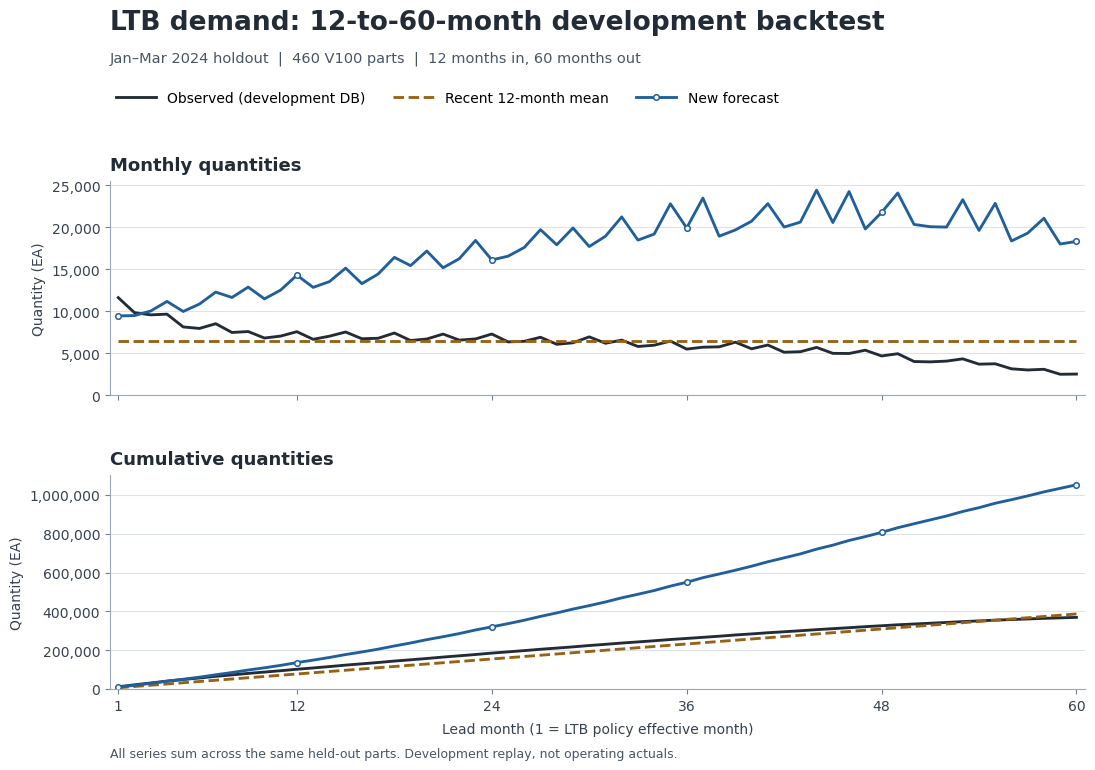

In [7]:
from IPython.display import display
import matplotlib.pyplot as plt

fig = build_ltb_dev12_figure(curves, n_parts=len(scored_all["observed"]))
fig.savefig(root / "ltb_dev12_observed_forecast.png", dpi=170, facecolor="white")
display(fig)
plt.close(fig)


## 6. 해석

월별 배분 오차와 별도로 60개월 총량이 얼마나 달라졌는지 확인합니다.

In [8]:
pooled = {r["method"]: r for r in results if r["month"] == "pooled"}
main, flat = pooled["forecast"], pooled["baseline"]
display(Markdown(
    f"{main['parts']:,}개 부품의 60개월 총량: 개발 관측 {main['observed_qty']:,.0f} EA, "
    f"보정 모델 {main['forecast_qty']:,.0f} EA, 월평균 기준선 {flat['forecast_qty']:,.0f} EA. "
    f"총량 보정 후 예측이 기준선의 {main['forecast_qty']/flat['forecast_qty']:.2f}배로 증가했습니다. "
    f"누적 WAPE는 기준선 {flat['total_wape']:.2%} 대비 보정 모델 {main['total_wape']:.2%}로 높았습니다. "
    "월별 비중은 총량을 재배분할 뿐 이 총량 차이를 만들지 않습니다."
))


460개 부품의 60개월 총량: 개발 관측 368,881 EA, 보정 모델 1,051,731 EA, 월평균 기준선 386,500 EA. 총량 보정 후 예측이 기준선의 2.72배로 증가했습니다. 누적 WAPE는 기준선 27.29% 대비 보정 모델 188.79%로 높았습니다. 월별 비중은 총량을 재배분할 뿐 이 총량 차이를 만들지 않습니다.

## 부록: 월별 집계 SQL

읽기 전용 트랜잭션으로 실행한 조회입니다. Notebook 자체는 DB에 접속하지 않습니다.

```sql
-- Same V100 development snapshot as the 24→60 coverage audit.
-- Output at part × recorded month. Do not generate months or coalesce quantity.
WITH policy AS MATERIALIZED (
    SELECT company_cd, subs_cd, site_cd, oper_part_no, ltb_effective_dt AS origin,
           to_char(ltb_effective_dt - interval '12 months', 'YYYYMMDD') AS first_date,
           to_char(ltb_effective_dt + interval '60 months', 'YYYYMMDD') AS end_exclusive
    FROM dsdm.tb_hist_oper_part_ltb_policy
    WHERE company_cd = 'DSE' AND subs_cd = 'C100' AND site_cd = 'V100'
      AND source_data_classification = 'SYNTHETIC'
      AND policy_cd = 'SALES_START_PLUS_12M'
      AND source_load_run_id = 'm3-canonical-v3-50x-sh24-r1-20260808-db-full-load-18-v1'
      AND ltb_effective_dt IN ('2019-01-01', '2019-02-01', '2019-03-01',
                               '2024-01-01', '2024-02-01', '2024-03-01')
)
SELECT md5(concat_ws('|',p.company_cd,p.subs_cd,p.site_cd,p.oper_part_no)) AS part_key,
       p.origin, left(d.order_dt, 6) AS month_key,
       sum(d.order_qty) AS qty,
       count(d.order_dt) FILTER (
           WHERE d.order_qty IS NULL OR d.order_qty::text IN ('NaN', 'Infinity', '-Infinity')
       ) AS bad_qty,
       count(d.order_dt) FILTER (WHERE nullif(btrim(d.qty_uom),'') IS NULL) AS unit_missing_count,
       min(nullif(upper(btrim(d.qty_uom)),'')) AS unit_min,
       max(nullif(upper(btrim(d.qty_uom)),'')) AS unit_max,
       count(d.order_dt) AS source_rows,
       count(d.order_dt) FILTER (WHERE d.create_id = 'synthetic_demand_parts') AS canonical_marker_rows,
       count(d.order_dt) FILTER (WHERE d.create_id <> 'synthetic_demand_parts') AS other_marker_rows
FROM policy p
LEFT JOIN dsdm.tb_dyn_demand_dtl d
  ON d.company_cd = 'DSE' AND d.subs_cd = 'C100' AND d.site_cd = 'V100'
 AND (d.company_cd,d.subs_cd,d.site_cd,d.part_no) = (p.company_cd,p.subs_cd,p.site_cd,p.oper_part_no)
 AND d.order_dt >= '20180101' AND d.order_dt < '20290301'
 AND d.order_dt >= p.first_date AND d.order_dt < p.end_exclusive
 AND coalesce(d.del_flag,'N') <> 'Y'
GROUP BY p.company_cd,p.subs_cd,p.site_cd,p.oper_part_no,p.origin,left(d.order_dt,6)
ORDER BY origin, part_key, month_key;

```